## 1. Setup

In [1]:
from pathlib import Path
from itertools import combinations

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import display
from scipy.stats import ks_2samp
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from sklearn.model_selection import train_test_split

pd.set_option("display.max_rows", 100)
pd.set_option("display.max_columns", 100)

### Project configuration

In [2]:
ROOT = Path.cwd()
while not (ROOT / "config" / "config.yaml").is_file():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("Could not find config/config.yaml")
    ROOT = ROOT.parent

CONFIG_PATH = ROOT / "config" / "config.yaml"
with CONFIG_PATH.open(encoding="utf-8") as file:
    cfg = yaml.safe_load(file)

PARQUET_DIR = ROOT / cfg["paths"]["parquet_dir"] / "v2"
DUCKDB_CONFIG = cfg["duckdb"]
print(f"Project root: {ROOT}")
print(f"Parquet directory: {PARQUET_DIR}")

Project root: /home/luca-zerella/Scrivania/intrusion_detection
Parquet directory: /home/luca-zerella/Scrivania/intrusion_detection/data/parquet/v2


### DuckDB connection

In [3]:
THREADS = 3  # Easy-to-edit thread limit
con = duckdb.connect()
con.execute(f"PRAGMA threads={THREADS}")
con.execute(f"PRAGMA memory_limit='{DUCKDB_CONFIG['memory_limit']}'")
temp_directory = (ROOT / DUCKDB_CONFIG["temp_directory"]).resolve()
temp_directory.mkdir(parents=True, exist_ok=True)
temp_sql_path = str(temp_directory).replace("'", "''")
con.execute(f"PRAGMA temp_directory='{temp_sql_path}'")

parquet_glob = str(PARQUET_DIR / "*.parquet").replace("'", "''")
con.execute(f"CREATE OR REPLACE VIEW flows AS SELECT * FROM read_parquet('{parquet_glob}')")

def q(sql):
    return con.execute(sql).df()

def sql_ident(name):
    return '"' + str(name).replace('"', '""') + '"'

def show_plot(fig):
    fig.tight_layout()
    plt.show()

print("DuckDB connection and flows view are ready.")

DuckDB connection and flows view are ready.


## 2. Dataset structure

In [4]:
schema = q("DESCRIBE flows")
ALL_COLUMNS = schema["column_name"].tolist()
print(f"Columns: {len(ALL_COLUMNS)}")
display(schema)

Columns: 47


,column_name,column_type,null,key,default,extra
0,row_id,BIGINT,YES,None,None,None
1,Dataset,VARCHAR,YES,None,None,None
2,IPV4_SRC_ADDR,VARCHAR,YES,None,None,None
3,L4_SRC_PORT,INTEGER,YES,None,None,None
4,IPV4_DST_ADDR,VARCHAR,YES,None,None,None
5,L4_DST_PORT,INTEGER,YES,None,None,None
6,PROTOCOL,INTEGER,YES,None,None,None
7,L7_PROTO,DOUBLE,YES,None,None,None
8,IN_BYTES,BIGINT,YES,None,None,None
9,IN_PKTS,BIGINT,YES,None,None,None


In [5]:
total_rows = int(q("SELECT COUNT(*) AS total_rows FROM flows").iloc[0]["total_rows"])
rows_by_dataset = q("SELECT Dataset, COUNT(*) AS rows FROM flows GROUP BY Dataset ORDER BY Dataset")
print(f"Total rows: {total_rows:,}")
display(rows_by_dataset)
# Full-table row counts are useful for comparison with the official dataset counts.

Total rows: 75,987,976


,Dataset,rows
0,NF-BoT-IoT,37763497
1,NF-CSE-CIC-IDS2018,18893708
2,NF-ToN-IoT,16940496
3,NF-UNSW-NB15,2390275


In [6]:
EXPECTED_COLUMNS = """row_id IPV4_SRC_ADDR L4_SRC_PORT IPV4_DST_ADDR L4_DST_PORT PROTOCOL L7_PROTO IN_BYTES IN_PKTS OUT_BYTES OUT_PKTS TCP_FLAGS CLIENT_TCP_FLAGS SERVER_TCP_FLAGS FLOW_DURATION_MILLISECONDS DURATION_IN DURATION_OUT MIN_TTL MAX_TTL LONGEST_FLOW_PKT SHORTEST_FLOW_PKT MIN_IP_PKT_LEN MAX_IP_PKT_LEN SRC_TO_DST_SECOND_BYTES DST_TO_SRC_SECOND_BYTES RETRANSMITTED_IN_BYTES RETRANSMITTED_IN_PKTS RETRANSMITTED_OUT_BYTES RETRANSMITTED_OUT_PKTS SRC_TO_DST_AVG_THROUGHPUT DST_TO_SRC_AVG_THROUGHPUT NUM_PKTS_UP_TO_128_BYTES NUM_PKTS_128_TO_256_BYTES NUM_PKTS_256_TO_512_BYTES NUM_PKTS_512_TO_1024_BYTES NUM_PKTS_1024_TO_1514_BYTES TCP_WIN_MAX_IN TCP_WIN_MAX_OUT ICMP_TYPE ICMP_IPV4_TYPE DNS_QUERY_ID DNS_QUERY_TYPE DNS_TTL_ANSWER FTP_COMMAND_RET_CODE Label Attack Dataset""".split()
v3_only_columns = ["FLOW_START_MILLISECONDS", "FLOW_END_MILLISECONDS", "SRC_TO_DST_IAT_MIN", "SRC_TO_DST_IAT_MAX", "SRC_TO_DST_IAT_AVG", "SRC_TO_DST_IAT_STDDEV", "DST_TO_SRC_IAT_MIN", "DST_TO_SRC_IAT_MAX", "DST_TO_SRC_IAT_AVG", "DST_TO_SRC_IAT_STDDEV"]
missing_columns = sorted(set(EXPECTED_COLUMNS) - set(ALL_COLUMNS))
extra_columns = sorted(set(ALL_COLUMNS) - set(EXPECTED_COLUMNS))
print("Missing expected columns")
display(pd.DataFrame({"column": missing_columns}))
print("Extra columns")
display(pd.DataFrame({"column": extra_columns}))
present_v3_columns = sorted(set(v3_only_columns) & set(ALL_COLUMNS))
print("v3-only timestamp or IAT columns present:", present_v3_columns)

Missing expected columns


,column


Extra columns


,column


v3-only timestamp or IAT columns present: []


In [7]:
row_id_check = q("""SELECT Dataset, COUNT(*) AS rows, COUNT(row_id) AS non_null_row_ids, COUNT(DISTINCT row_id) AS distinct_row_ids, COUNT(*) - COUNT(row_id) AS null_row_ids FROM flows GROUP BY Dataset ORDER BY Dataset""")
row_id_check["unique_within_dataset"] = row_id_check["rows"] == row_id_check["distinct_row_ids"]
display(row_id_check)
# row_id restarts at zero in each Parquet file, so uniqueness is checked within Dataset.

,Dataset,rows,non_null_row_ids,distinct_row_ids,null_row_ids,unique_within_dataset
0,NF-BoT-IoT,37763497,37763497,37763497,0,True
1,NF-CSE-CIC-IDS2018,18893708,18893708,18893708,0,True
2,NF-ToN-IoT,16940496,16940496,16940496,0,True
3,NF-UNSW-NB15,2390275,2390275,2390275,0,True


#### Osservazioni
- Ci sono 75.987.976 flussi e 47 colonne, tutte quelle attese. Mancano le colonne con timestamp e IAT della v3.
- Il peso dei sub-dataset è molto sbilanciato: BoT-IoT 49,7%, CSE-CIC-IDS2018 24,9%, ToN-IoT 22,3%, UNSW-NB15 3,1% (circa 16 a 1 tra il primo e l'ultimo).
- `row_id` è unico solo dentro ogni `Dataset`, perché riparte da 0 per ogni file. Non rispetta l'ordine di cattura dei flussi.

#### Note per la pulizia
- Identificare ogni riga con la coppia `(Dataset, row_id)` e non usare `row_id` e `Dataset` come feature.

#### Note per l'addestramento
- BoT-IoT pesa quasi metà dei dati: servono pesi o campionamento, e le metriche vanno riportate per fonte.
- Non costruire sequenze usando l'ordine di `row_id`.

## 3. Data integrity

In [8]:
column_names = ALL_COLUMNS
null_parts = [f"COUNT(*) FILTER (WHERE {sql_ident(c)} IS NULL) AS {sql_ident(c)}" for c in column_names]
float_columns = schema.loc[schema["column_type"].str.upper().str.contains("DOUBLE|FLOAT|REAL"), "column_name"].tolist()
nan_inf_parts = []
for c in float_columns:
    x = sql_ident(c)
    nan_inf_parts.append(f"COUNT(*) FILTER (WHERE isnan({x}) OR isinf({x})) AS {sql_ident(c)}")
null_sql = ", ".join(null_parts) if null_parts else "0 AS no_columns"
nan_inf_sql = ", ".join(nan_inf_parts) if nan_inf_parts else "0 AS no_float_columns"
quality_counts = q(f"SELECT COUNT(*) AS rows, {null_sql}, {nan_inf_sql} FROM flows").iloc[0]
total_null_cells = int(quality_counts[column_names].sum()) if column_names else 0
nan_inf_count = int(quality_counts[float_columns].sum()) if float_columns else 0
print(f"NULL cells: {total_null_cells:,}; NaN/Inf values in floating-point columns: {nan_inf_count:,}")

NULL cells: 0; NaN/Inf values in floating-point columns: 0


In [9]:
feature_columns = [c for c in ALL_COLUMNS if c not in {"row_id", "Dataset"}]
feature_sql = ", ".join(sql_ident(c) for c in feature_columns)
# Exact duplicate grouping is a full-table operation; row_id is excluded because it is unique by design.
exact_duplicate_groups = q(f"SELECT Dataset, COUNT(*) AS groups, SUM(n - 1) AS duplicated_rows FROM (SELECT Dataset, {feature_sql}, COUNT(*) AS n FROM flows GROUP BY Dataset, {feature_sql} HAVING COUNT(*) > 1) GROUP BY Dataset")
exact_duplicate_rows = int(exact_duplicate_groups["duplicated_rows"].sum()) if len(exact_duplicate_groups) else 0
exact_duplicate_pct = 100.0 * exact_duplicate_rows / total_rows if total_rows else 0.0
display(exact_duplicate_groups)
print(f"Duplicated rows: {exact_duplicate_rows:,} ({exact_duplicate_pct:.4f}%)")

,Dataset,groups,duplicated_rows
0,NF-BoT-IoT,120210,120210.0


Duplicated rows: 120,210 (0.1582%)


In [10]:
conflict_key = [c for c in ALL_COLUMNS if c not in {"row_id", "Dataset", "Label", "Attack"}]
conflict_sql = ", ".join(sql_ident(c) for c in conflict_key)
# This full-table grouping excludes row_id and labels to find identical features with conflicting targets.
conflicting_label_groups = q(f"SELECT COUNT(*) AS conflicting_label_groups FROM (SELECT Dataset, {conflict_sql} FROM flows GROUP BY Dataset, {conflict_sql} HAVING COUNT(DISTINCT Label) > 1 OR COUNT(DISTINCT Attack) > 1)").iloc[0]["conflicting_label_groups"]
conflicting_label_groups = int(conflicting_label_groups)
print(f"Conflicting-label groups: {conflicting_label_groups:,}")

Conflicting-label groups: 5,384


In [11]:
conflict_diagnostic_key = [c for c in ALL_COLUMNS if c not in {"row_id", "Dataset", "Label", "Attack"}]
conflict_diagnostic_sql = ", ".join(sql_ident(c) for c in conflict_diagnostic_key)
conflict_group_summary = q(f"SELECT Dataset, CASE WHEN label_count > 1 THEN 'Benign vs Attack' ELSE 'Attack differs' END AS conflict_type, COUNT(*) AS groups, SUM(group_rows) AS rows_involved, MAX(group_rows) AS largest_group FROM (SELECT Dataset, {conflict_diagnostic_sql}, COUNT(*) AS group_rows, COUNT(DISTINCT Label) AS label_count, COUNT(DISTINCT Attack) AS attack_count FROM flows GROUP BY Dataset, {conflict_diagnostic_sql} HAVING COUNT(DISTINCT Label) > 1 OR COUNT(DISTINCT Attack) > 1) GROUP BY Dataset, conflict_type ORDER BY Dataset, conflict_type")
display(conflict_group_summary)

,Dataset,conflict_type,groups,rows_involved,largest_group
0,NF-CSE-CIC-IDS2018,Attack differs,2934,5922.0,3
1,NF-UNSW-NB15,Attack differs,2450,14488.0,7


In [12]:
conflict_label_pairs = q(f"SELECT Dataset, label_set, attack_set, COUNT(*) AS groups FROM (SELECT Dataset, {conflict_diagnostic_sql}, string_agg(DISTINCT CAST(Label AS VARCHAR), ' | ') AS label_set, string_agg(DISTINCT CAST(Attack AS VARCHAR), ' | ') AS attack_set, COUNT(DISTINCT Label) AS label_count, COUNT(DISTINCT Attack) AS attack_count FROM flows GROUP BY Dataset, {conflict_diagnostic_sql} HAVING COUNT(DISTINCT Label) > 1 OR COUNT(DISTINCT Attack) > 1) GROUP BY Dataset, label_set, attack_set ORDER BY groups DESC LIMIT 50")
display(conflict_label_pairs)

,Dataset,label_set,attack_set,groups
0,NF-CSE-CIC-IDS2018,1,DDOS attack-HOIC | Brute Force -Web,899
1,NF-CSE-CIC-IDS2018,1,Brute Force -Web | DDOS attack-HOIC,847
2,NF-CSE-CIC-IDS2018,1,Brute Force -XSS | DDOS attack-HOIC,382
3,NF-CSE-CIC-IDS2018,1,DDOS attack-HOIC | Brute Force -XSS,356
4,NF-CSE-CIC-IDS2018,1,SQL Injection | DDOS attack-HOIC,179
5,NF-CSE-CIC-IDS2018,1,DDOS attack-HOIC | SQL Injection,159
6,NF-UNSW-NB15,1,Exploits | Generic,37
7,NF-UNSW-NB15,1,DoS | Exploits,37
8,NF-UNSW-NB15,1,Generic | Exploits,35
9,NF-UNSW-NB15,1,Exploits | DoS,31


In [13]:
conflict_duplicate_overlap = q(f"SELECT Dataset, COUNT(*) AS conflicting_groups, SUM(group_rows) AS conflicting_rows, SUM(duplicate_rows) AS repeated_rows_within_target_variants FROM (SELECT Dataset, {conflict_diagnostic_sql}, SUM(target_rows) AS group_rows, SUM(target_rows - 1) AS duplicate_rows, COUNT(DISTINCT Label) AS label_count, COUNT(DISTINCT Attack) AS attack_count FROM (SELECT Dataset, {conflict_diagnostic_sql}, Label, Attack, COUNT(*) AS target_rows FROM flows GROUP BY Dataset, {conflict_diagnostic_sql}, Label, Attack) GROUP BY Dataset, {conflict_diagnostic_sql} HAVING COUNT(DISTINCT Label) > 1 OR COUNT(DISTINCT Attack) > 1) GROUP BY Dataset ORDER BY Dataset")
display(conflict_duplicate_overlap)
conflict_split_risk = q(f"SELECT Dataset, COUNT(*) AS conflicting_groups, SUM(1 - POWER(0.75, group_rows) - POWER(0.25, group_rows)) AS expected_groups_crossing_random_75_25_split, SUM(group_rows * (0.75 * (1 - POWER(0.75, group_rows - 1)) + 0.25 * (1 - POWER(0.25, group_rows - 1)))) AS expected_rows_with_same_feature_group_across_splits FROM (SELECT Dataset, {conflict_diagnostic_sql}, COUNT(*) AS group_rows, COUNT(DISTINCT Label) AS label_count, COUNT(DISTINCT Attack) AS attack_count FROM flows GROUP BY Dataset, {conflict_diagnostic_sql} HAVING COUNT(DISTINCT Label) > 1 OR COUNT(DISTINCT Attack) > 1) GROUP BY Dataset ORDER BY Dataset")
display(conflict_split_risk)
# These are analytical expectations under independent 75/25 row assignment, not a simulated split.

,Dataset,conflicting_groups,conflicting_rows,repeated_rows_within_target_variants
0,NF-CSE-CIC-IDS2018,2934,5922.0,0.0
1,NF-UNSW-NB15,2450,14488.0,0.0


,Dataset,conflicting_groups,expected_groups_crossing_random_75_25_split,expected_rows_with_same_feature_group_across_splits
0,NF-CSE-CIC-IDS2018,2934,1110.375000,2251.125000
1,NF-UNSW-NB15,2450,1913.586182,11957.252197


In [14]:
domains = {"L4_SRC_PORT": (0, 65535), "L4_DST_PORT": (0, 65535), "PROTOCOL": (0, 255), "TCP_FLAGS": (0, 255), "CLIENT_TCP_FLAGS": (0, 255), "SERVER_TCP_FLAGS": (0, 255), "MIN_TTL": (0, 255), "MAX_TTL": (0, 255)}
for c in ["IN_BYTES", "IN_PKTS", "OUT_BYTES", "OUT_PKTS", "FLOW_DURATION_MILLISECONDS", "DURATION_IN", "DURATION_OUT", "LONGEST_FLOW_PKT", "SHORTEST_FLOW_PKT", "MIN_IP_PKT_LEN", "MAX_IP_PKT_LEN", "SRC_TO_DST_SECOND_BYTES", "DST_TO_SRC_SECOND_BYTES", "RETRANSMITTED_IN_BYTES", "RETRANSMITTED_IN_PKTS", "RETRANSMITTED_OUT_BYTES", "RETRANSMITTED_OUT_PKTS", "L7_PROTO"]:
    domains[c] = (0, None)
domain_checks = []
for c, (lower, upper) in domains.items():
    if c not in ALL_COLUMNS:
        continue
    x = sql_ident(c)
    conditions = [f"{x} < {lower}"]
    if upper is not None:
        conditions.append(f"{x} > {upper}")
    domain_checks.append(f"COUNT(*) FILTER (WHERE {' OR '.join(conditions)}) AS {sql_ident(c)}")
out_domain_sql = ", ".join(domain_checks) if domain_checks else "0 AS no_domain_checks"
out_domain_values = q(f"SELECT {out_domain_sql} FROM flows").iloc[0]
out_of_domain_count = int(out_domain_values.sum())
out_of_domain_table = pd.DataFrame({"feature": list(out_domain_values.index), "violations": list(out_domain_values.values)})
display(out_of_domain_table[out_of_domain_table["violations"] > 0])
print(f"Out-of-domain values: {out_of_domain_count:,}")

,feature,violations


Out-of-domain values: 0


In [15]:
rules = [("MIN_TTL", "MAX_TTL"), ("SHORTEST_FLOW_PKT", "LONGEST_FLOW_PKT"), ("MIN_IP_PKT_LEN", "MAX_IP_PKT_LEN")]
violation_conditions = []
for a, b in rules:
    if {a, b}.issubset(ALL_COLUMNS):
        violation_conditions.append((f"{a} <= {b}", f"{sql_ident(a)} > {sql_ident(b)}"))
if {"DURATION_IN", "FLOW_DURATION_MILLISECONDS"}.issubset(ALL_COLUMNS):
    violation_conditions.append(("DURATION_IN <= FLOW_DURATION_MILLISECONDS", "DURATION_IN > FLOW_DURATION_MILLISECONDS"))
if {"DURATION_OUT", "FLOW_DURATION_MILLISECONDS"}.issubset(ALL_COLUMNS):
    violation_conditions.append(("DURATION_OUT <= FLOW_DURATION_MILLISECONDS", "DURATION_OUT > FLOW_DURATION_MILLISECONDS"))
for packets, byte_count in [("IN_PKTS", "IN_BYTES"), ("OUT_PKTS", "OUT_BYTES")]:
    if {packets, byte_count}.issubset(ALL_COLUMNS):
        violation_conditions.append((f"{packets} = 0 implies {byte_count} = 0", f"{sql_ident(packets)} = 0 AND {sql_ident(byte_count)} <> 0"))
for retransmitted, total in [("RETRANSMITTED_IN_BYTES", "IN_BYTES"), ("RETRANSMITTED_OUT_BYTES", "OUT_BYTES")]:
    if {retransmitted, total}.issubset(ALL_COLUMNS):
        violation_conditions.append((f"{retransmitted} <= {total}", f"{sql_ident(retransmitted)} > {sql_ident(total)}"))
consistency_parts = [f"COUNT(*) FILTER (WHERE {condition}) AS {sql_ident(name)}" for name, condition in violation_conditions]
consistency_sql = ", ".join(consistency_parts) if consistency_parts else "0 AS no_consistency_checks"
consistency_values = q(f"SELECT {consistency_sql} FROM flows").iloc[0]
consistency_violations = int(consistency_values.sum())
display(pd.DataFrame({"rule": consistency_values.index, "violations": consistency_values.values}))

,rule,violations
0,MIN_TTL <= MAX_TTL,0
1,SHORTEST_FLOW_PKT <= LONGEST_FLOW_PKT,0
2,MIN_IP_PKT_LEN <= MAX_IP_PKT_LEN,0
3,DURATION_IN <= FLOW_DURATION_MILLISECONDS,0
4,DURATION_OUT <= FLOW_DURATION_MILLISECONDS,0
5,IN_PKTS = 0 implies IN_BYTES = 0,0
6,OUT_PKTS = 0 implies OUT_BYTES = 0,0
7,RETRANSMITTED_IN_BYTES <= IN_BYTES,0
8,RETRANSMITTED_OUT_BYTES <= OUT_BYTES,0


#### Osservazioni
- Non ci sono NULL, NaN/Inf, valori fuori dominio né violazioni delle 9 regole di consistenza (sono controlli semplici: limiti minimi e ordinamenti).
- Ci sono 120.210 duplicati esatti (0,16% del totale, 0,32% di BoT-IoT), tutti in BoT-IoT. Non sappiamo se sono flussi ripetuti davvero o copie.
- 5.384 gruppi di righe (20.410 righe, 0,03%) hanno feature identiche ma `Attack` diverso. `Label` è sempre 1, quindi non c'è mai un conflitto tra benigno e attacco. Succede solo in CSE-CIC (2.934 gruppi) e UNSW-NB15 (2.450 gruppi).
- In CSE-CIC il conflitto è quasi sempre `DDOS attack-HOIC` contro `Brute Force -Web` (1.746 gruppi), `Brute Force -XSS` (738) e `SQL Injection` (338). Almeno l'81%, l'80% e il 78% delle righe di queste tre classi ha una riga HOIC identica. Sono limiti inferiori, perché ogni variante compare una sola volta per gruppo.
- In UNSW-NB15 `Exploits` va in conflitto con `Generic`, `DoS`, `Reconnaissance` e `Fuzzers`. Alcuni gruppi hanno fino a 5 classi (`Analysis`, `Backdoor`, `DoS`, `Exploits`, `Fuzzers`).
- In CSE-CIC e UNSW-NB15 non ci sono duplicati esatti con la stessa etichetta, ma ci sono righe identiche con etichette diverse. `[ipotesi]` il dataset originale potrebbe essere stato deduplicato per classe, oppure le finestre di attacco si sovrappongono.
- Con uno split casuale 75/25, circa 2.251 righe in conflitto di CSE-CIC (38%) e 11.957 di UNSW-NB15 (82,5%) finirebbero con la riga gemella nell'altro split.

#### Note per la pulizia
- Duplicati: non toglierli alla cieca. Prima si raggruppano e si deduplica, poi si fa lo split.
- Conflitti: non eliminare i gruppi. Nel binario non serve fare nulla. Nel multiclasse queste classi non si distinguono con le feature attuali: decidere se tenerle separate nei risultati o raggrupparle in una famiglia (es. attacchi web).

#### Note per l'addestramento
- Fare lo split per gruppi di feature identiche, così nessuna copia finisce sia in train sia in test.
- Nel multiclasse, per le classi in conflitto la recall massima è limitata dai dati stessi: riportare le metriche sia per classe sia per famiglia.

## 4. Class distribution

In [16]:
label_counts = q("SELECT Label, COUNT(*) AS rows, 100.0 * COUNT(*) / SUM(COUNT(*)) OVER () AS percentage FROM flows GROUP BY Label ORDER BY rows DESC")
attack_counts = q("SELECT Attack, COUNT(*) AS rows, 100.0 * COUNT(*) / SUM(COUNT(*)) OVER () AS percentage FROM flows GROUP BY Attack ORDER BY rows DESC")
display(label_counts)
display(attack_counts)

,Label,rows,percentage
0,1,50822681,66.88253
1,0,25165295,33.11747


,Attack,rows,percentage
0,Benign,25165295,33.117470
1,DDoS,18331847,24.124668
2,DoS,16678977,21.949495
3,scanning,3781419,4.976339
4,Reconnaissance,2633778,3.466046
5,xss,2455020,3.230801
6,ddos,2026234,2.666519
7,password,1153323,1.517770
8,DDOS attack-HOIC,1080858,1.422407
9,dos,712609,0.937792


Majority-to-minority class ratio: 2.02


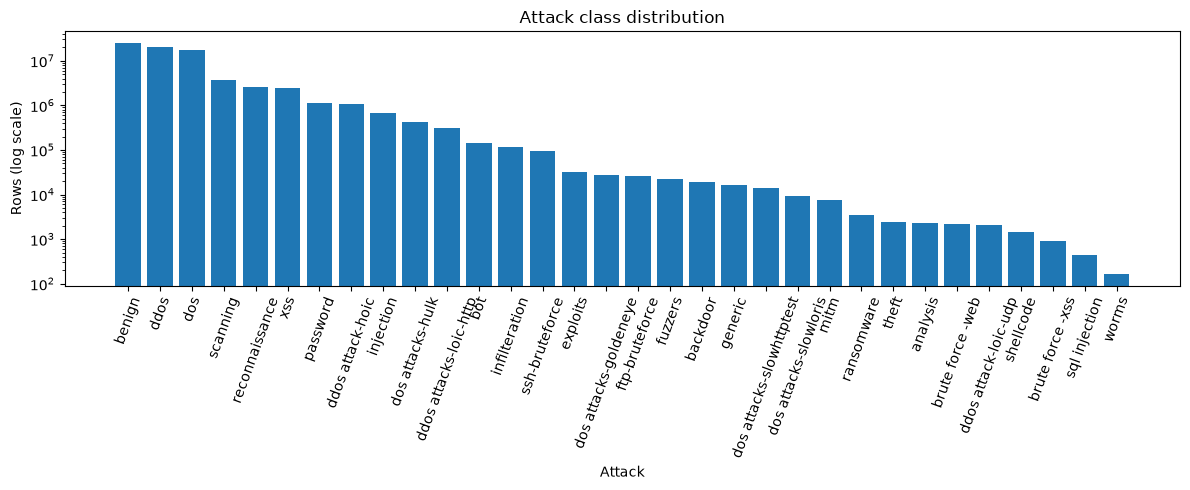

In [17]:
label_sizes = label_counts["rows"]
imbalance_ratio = float(label_sizes.max() / label_sizes.min()) if len(label_sizes) and label_sizes.min() else np.nan
print(f"Majority-to-minority class ratio: {imbalance_ratio:.2f}")

attack_counts_plot = (
    attack_counts
    .assign(
        Attack_norm=attack_counts["Attack"]
        .astype(str)
        .str.strip()
        .str.casefold()
    )
    .groupby("Attack_norm", as_index=False)["rows"]
    .sum()
    .sort_values("rows", ascending=False, kind="stable")
)

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(attack_counts_plot["Attack_norm"], attack_counts_plot["rows"])
ax.set_yscale("log")
ax.set_title("Attack class distribution")
ax.set_xlabel("Attack")
ax.set_ylabel("Rows (log scale)")
ax.tick_params(axis="x", rotation=70)
show_plot(fig)

In [18]:
dataset_labels = q("SELECT Dataset, Label, COUNT(*) AS rows FROM flows GROUP BY Dataset, Label ORDER BY Dataset, Label")
dataset_label_pct = dataset_labels.pivot(index="Dataset", columns="Label", values="rows").fillna(0)
for label in dataset_label_pct.columns:
    dataset_label_pct[f"Label {label} percentage"] = 100 * dataset_label_pct[label] / dataset_label_pct.sum(axis=1)
display(dataset_labels)
display(dataset_label_pct.reset_index())

,Dataset,Label,rows
0,NF-BoT-IoT,0,135037
1,NF-BoT-IoT,1,37628460
2,NF-CSE-CIC-IDS2018,0,16635567
3,NF-CSE-CIC-IDS2018,1,2258141
4,NF-ToN-IoT,0,6099469
5,NF-ToN-IoT,1,10841027
6,NF-UNSW-NB15,0,2295222
7,NF-UNSW-NB15,1,95053


Label,Dataset,0,1,Label 0 percentage,Label 1 percentage
0,NF-BoT-IoT,135037,37628460,0.357586,99.642413
1,NF-CSE-CIC-IDS2018,16635567,2258141,88.048185,11.951759
2,NF-ToN-IoT,6099469,10841027,36.005256,63.994608
3,NF-UNSW-NB15,2295222,95053,96.023345,3.976496


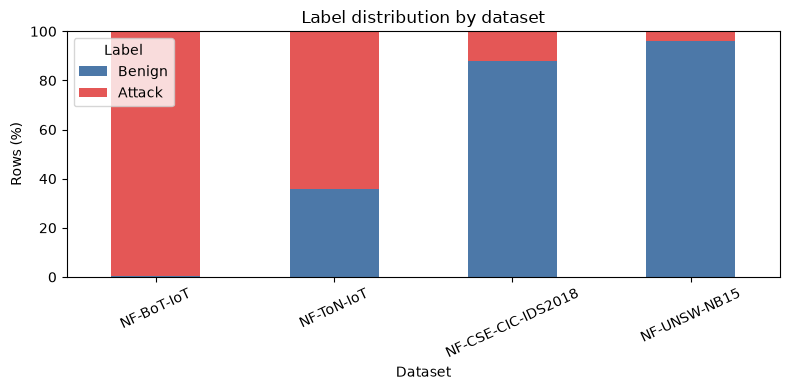

In [19]:
label_values = sorted(dataset_labels["Label"].dropna().unique())
percentage_columns = [f"Label {label} percentage" for label in label_values]

label_plot = dataset_label_pct[percentage_columns].copy()
label_plot = label_plot.loc[dataset_label_pct["Label 1 percentage"].sort_values(ascending=False, kind="stable").index]
label_plot.columns = [
    "Benign" if label == 0 else "Attack" if label == 1 else f"Label {label}"
    for label in label_values
]

label_colors = [
    "#4C78A8" if label == 0 else "#E45756" if label == 1 else "#72B7B2"
    for label in label_values
]

fig, ax = plt.subplots(figsize=(8, 4))
label_plot.plot(kind="bar", stacked=True, color=label_colors, ax=ax)
ax.set_title("Label distribution by dataset")
ax.set_xlabel("Dataset")
ax.set_ylabel("Rows (%)")
ax.set_ylim(0, 100)
ax.legend(title="Label")
ax.tick_params(axis="x", rotation=25)
show_plot(fig)

#### Osservazioni
- Gli attacchi sono il 66,9% del totale, ma dipende dalla fonte: 99,6% in BoT-IoT, 64,0% in ToN-IoT, 12,0% in CSE-CIC-IDS2018, 4,0% in UNSW-NB15. In BoT-IoT i benigni sono solo 135.037 (0,36%).
- `Attack` ha 35 valori. `DDoS` (24,1%) e `DoS` (21,9%) dominano: `DDoS` ha 18.331.847 righe, `Worms` solo 164. Dieci classi stanno sotto lo 0,01%.
- Ci sono varianti di maiuscole (`DoS`/`dos`, `DDoS`/`ddos`, `Backdoor`/`backdoor`) e un refuso (`Infilteration`). Classi con lo stesso nome o simile in fonti diverse non sono per forza la stessa cosa: ad esempio `xss` di ToN-IoT ha 2.455.020 righe, `Brute Force -XSS` di CSE-CIC solo 927.

#### Note per la pulizia
- Normalizzare i nomi (`casefold` e `strip`) in una colonna separata dall'accorpamento per significato (`Attack_raw`, `Attack_norm`, eventuale famiglia). Ogni accorpamento va motivato.

#### Note per l'addestramento
- Usare macro-F1, recall e PR-AUC per classe e per fonte, con split stratificato per `Dataset` e classe.
- Accorpare o togliere le classi rare è una scelta da valutare, non un automatismo.

## 5. Feature distributions

In [20]:
GROUPS = {
    "identifiers and metadata": ["row_id", "Dataset"],
    "IP addresses and ports": ["IPV4_SRC_ADDR", "IPV4_DST_ADDR", "L4_SRC_PORT", "L4_DST_PORT"],
    "protocols and flags": ["PROTOCOL", "L7_PROTO", "TCP_FLAGS", "CLIENT_TCP_FLAGS", "SERVER_TCP_FLAGS", "ICMP_TYPE", "ICMP_IPV4_TYPE", "DNS_QUERY_ID", "DNS_QUERY_TYPE", "FTP_COMMAND_RET_CODE"],
    "bytes and packets": ["IN_BYTES", "IN_PKTS", "OUT_BYTES", "OUT_PKTS", "NUM_PKTS_UP_TO_128_BYTES", "NUM_PKTS_128_TO_256_BYTES", "NUM_PKTS_256_TO_512_BYTES", "NUM_PKTS_512_TO_1024_BYTES", "NUM_PKTS_1024_TO_1514_BYTES"],
    "durations": ["FLOW_DURATION_MILLISECONDS", "DURATION_IN", "DURATION_OUT"],
    "TTL and packet sizes": ["MIN_TTL", "MAX_TTL", "LONGEST_FLOW_PKT", "SHORTEST_FLOW_PKT", "MIN_IP_PKT_LEN", "MAX_IP_PKT_LEN"],
    "throughput": ["SRC_TO_DST_SECOND_BYTES", "DST_TO_SRC_SECOND_BYTES", "SRC_TO_DST_AVG_THROUGHPUT", "DST_TO_SRC_AVG_THROUGHPUT"],
    "retransmissions": ["RETRANSMITTED_IN_BYTES", "RETRANSMITTED_IN_PKTS", "RETRANSMITTED_OUT_BYTES", "RETRANSMITTED_OUT_PKTS"],
    "TCP windows and DNS": ["TCP_WIN_MAX_IN", "TCP_WIN_MAX_OUT", "DNS_TTL_ANSWER"],
    "targets": ["Label", "Attack"],
}
assigned = {c: group for group, cols in GROUPS.items() for c in cols}
unclassified_columns = [c for c in ALL_COLUMNS if c not in assigned]
print("Unclassified columns:", unclassified_columns)
display(pd.DataFrame([{"column": c, "group": assigned.get(c, "unclassified")} for c in ALL_COLUMNS]))

Unclassified columns: []


,column,group
0,row_id,identifiers and metadata
1,Dataset,identifiers and metadata
2,IPV4_SRC_ADDR,IP addresses and ports
3,L4_SRC_PORT,IP addresses and ports
4,IPV4_DST_ADDR,IP addresses and ports
5,L4_DST_PORT,IP addresses and ports
6,PROTOCOL,protocols and flags
7,L7_PROTO,protocols and flags
8,IN_BYTES,bytes and packets
9,IN_PKTS,bytes and packets


In [5]:
discrete_columns = {"row_id", "Label", "PROTOCOL", "L7_PROTO", "TCP_FLAGS", "CLIENT_TCP_FLAGS", "SERVER_TCP_FLAGS", "ICMP_TYPE", "ICMP_IPV4_TYPE", "DNS_QUERY_ID", "DNS_QUERY_TYPE", "FTP_COMMAND_RET_CODE", "L4_SRC_PORT", "L4_DST_PORT"}
numeric_columns = schema.loc[schema["column_type"].str.upper().str.contains("INT|DOUBLE|FLOAT|REAL"), "column_name"].tolist()
continuous = [c for c in numeric_columns if c not in discrete_columns]
print(f"Continuous features: {len(continuous)}")

Continuous features: 29


#### Zeri, costanti e valori sentinella

Non avere NULL non significa non avere valori mancanti: un mancante può essere scritto come 0. Le analisi seguenti guardano la quota di zeri per feature, fonte, classe e protocollo. Le soglie nel codice sono criteri esplorativi.

Dataset,NF-BoT-IoT,NF-CSE-CIC-IDS2018,NF-ToN-IoT,NF-UNSW-NB15
feature,,,,
FTP_COMMAND_RET_CODE,100.0%,100.0%,99.7%,81.9%
DNS_TTL_ANSWER,100.0%,60.0%,93.5%,85.0%
DNS_QUERY_TYPE,100.0%,59.2%,85.8%,84.5%
DNS_QUERY_ID,100.0%,59.2%,85.8%,84.5%
RETRANSMITTED_OUT_BYTES,100.0%,95.9%,98.1%,28.6%
RETRANSMITTED_OUT_PKTS,100.0%,95.9%,98.1%,28.6%
NUM_PKTS_1024_TO_1514_BYTES,99.9%,72.9%,87.8%,58.0%
NUM_PKTS_256_TO_512_BYTES,99.8%,61.5%,86.1%,68.7%
NUM_PKTS_512_TO_1024_BYTES,99.8%,61.5%,89.5%,79.9%


,feature,Dataset,rows,min,max,zero_rate,constant,all_zero
0,FTP_COMMAND_RET_CODE,NF-CSE-CIC-IDS2018,18893708,0.0,0.0,1.0,True,True


,feature,Dataset,zero_rate_0,rows_0,zero_rate_1,rows_1,gap
0,DURATION_IN,NF-CSE-CIC-IDS2018,96.6,16635567.0,17.4,2258141.0,79.2
1,FLOW_DURATION_MILLISECONDS,NF-CSE-CIC-IDS2018,96.0,16635567.0,17.3,2258141.0,78.7
2,DURATION_IN,NF-BoT-IoT,85.6,135037.0,8.2,37628460.0,77.4
3,MAX_TTL,NF-BoT-IoT,80.8,135037.0,7.7,37628460.0,73.1
4,MIN_TTL,NF-BoT-IoT,80.8,135037.0,7.7,37628460.0,73.1
5,MIN_IP_PKT_LEN,NF-BoT-IoT,16.7,135037.0,88.2,37628460.0,71.6
6,OUT_BYTES,NF-BoT-IoT,16.7,135037.0,88.2,37628460.0,71.6
7,OUT_PKTS,NF-BoT-IoT,16.7,135037.0,88.2,37628460.0,71.6
8,DST_TO_SRC_SECOND_BYTES,NF-BoT-IoT,16.7,135037.0,88.2,37628460.0,71.6
9,DST_TO_SRC_AVG_THROUGHPUT,NF-BoT-IoT,17.6,135037.0,88.2,37628460.0,70.6


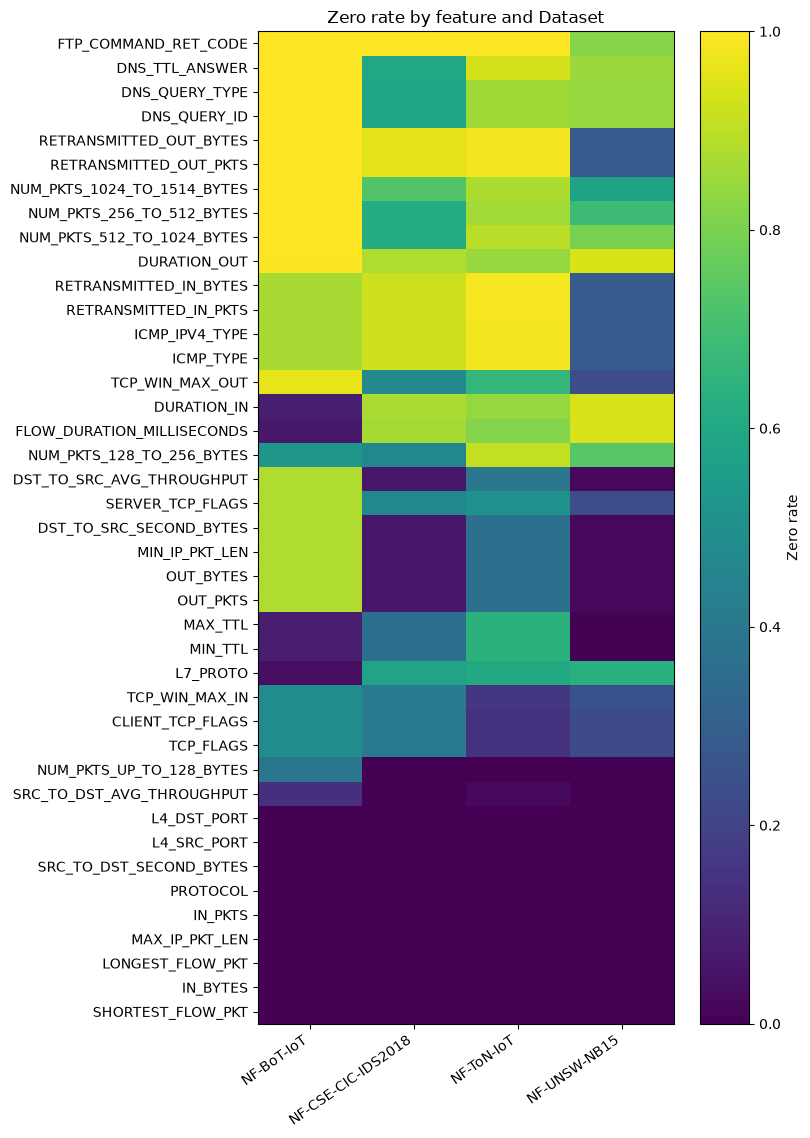

In [6]:
ZERO_RATE_SPARSE = 0.95
ZERO_RATE_GAP = 0.20

zero_columns = [c for c in numeric_columns if c not in {"row_id", "Label", "Attack", "Dataset"}]
zero_aggregates = ["COUNT(*) AS rows"]
for column in zero_columns:
    name = sql_ident(column)
    zero_aggregates.extend([
        f"COUNT(*) FILTER (WHERE {name} = 0) AS {sql_ident(column + '__zeros')}",
        f"MIN({name}) AS {sql_ident(column + '__min')}",
        f"MAX({name}) AS {sql_ident(column + '__max')}",
    ])
zero_wide = q("SELECT Dataset, Label, " + ", ".join(zero_aggregates) + " FROM flows GROUP BY Dataset, Label")
zero_records = []
for row in zero_wide.itertuples(index=False, name=None):
    dataset, label, rows, *values = row
    for j, feature in enumerate(zero_columns):
        zeros, minimum, maximum = values[j * 3:j * 3 + 3]
        zero_records.append({"Dataset": dataset, "Label": label, "feature": feature,
                             "rows": int(rows), "zeros": int(zeros), "zero_rate": zeros / rows if rows else float("nan"),
                             "min": minimum, "max": maximum})
zero_by_label = pd.DataFrame(zero_records)
zero_by_dataset = (zero_by_label.groupby(["Dataset", "feature"], as_index=False)
                   .agg(rows=("rows", "sum"), zeros=("zeros", "sum"), min=("min", "min"), max=("max", "max")))
zero_by_dataset["zero_rate"] = zero_by_dataset["zeros"] / zero_by_dataset["rows"]
zero_by_dataset["constant"] = zero_by_dataset["min"] == zero_by_dataset["max"]
zero_by_dataset["all_zero"] = zero_by_dataset["zero_rate"] == 1
zero_pivot = zero_by_dataset.pivot(index="feature", columns="Dataset", values="zero_rate")
zero_pivot["max_zero_rate"] = zero_pivot.max(axis=1)
zero_pivot = zero_pivot.sort_values("max_zero_rate", ascending=False).drop(columns="max_zero_rate")
display(zero_pivot.map(lambda value: f"{value:.1%}"))

display(zero_by_dataset.loc[zero_by_dataset["constant"] | zero_by_dataset["all_zero"],
                            ["feature", "Dataset", "rows", "min", "max", "zero_rate", "constant", "all_zero"]]
        .sort_values(["Dataset", "feature"]).reset_index(drop=True))

label_rates = zero_by_label.pivot(index=["feature", "Dataset"], columns="Label", values=["zero_rate", "rows"])
label_rates.columns = [f"{metric}_{label}" for metric, label in label_rates.columns]
label_rates = label_rates.reset_index()
label_rates = label_rates[(label_rates["rows_0"] >= 1000) & (label_rates["rows_1"] >= 1000)].copy()
label_rates["gap"] = (label_rates["zero_rate_1"] - label_rates["zero_rate_0"]).abs()
gap_cases = label_rates[label_rates["gap"] >= ZERO_RATE_GAP].copy()
for column in ["zero_rate_0", "zero_rate_1", "gap"]:
    gap_cases[column] = (100 * gap_cases[column]).round(1)
display(gap_cases[["feature", "Dataset", "zero_rate_0", "rows_0", "zero_rate_1", "rows_1", "gap"]]
        .sort_values("gap", ascending=False).reset_index(drop=True))

fig, ax = plt.subplots(figsize=(max(8, 1.8 * len(zero_pivot.columns)), max(6, 0.28 * len(zero_pivot))))
image = ax.imshow(zero_pivot.to_numpy(), aspect="auto", vmin=0, vmax=1, cmap="viridis")
ax.set_xticks(np.arange(len(zero_pivot.columns)), labels=zero_pivot.columns, rotation=35, ha="right")
ax.set_yticks(np.arange(len(zero_pivot.index)), labels=zero_pivot.index)
ax.set_title("Zero rate by feature and Dataset")
fig.colorbar(image, ax=ax, label="Zero rate")
show_plot(fig)

#### Zeri strutturali o sospetti

Uno zero può essere un valore valido, un campo che non si applica o una sentinella. `ICMP_TYPE=0`, ad esempio, non è per forza un mancante. Il controllo sui valori fuori protocollo assume TCP=6 e ICMP=1.

In [7]:
proto_class = "CASE PROTOCOL WHEN 6 THEN 'TCP' WHEN 17 THEN 'UDP' WHEN 1 THEN 'ICMP' ELSE 'other' END"
protocol_families = {
    "TCP": ["TCP_FLAGS", "CLIENT_TCP_FLAGS", "SERVER_TCP_FLAGS", "TCP_WIN_MAX_IN", "TCP_WIN_MAX_OUT",
            "RETRANSMITTED_IN_BYTES", "RETRANSMITTED_IN_PKTS", "RETRANSMITTED_OUT_BYTES", "RETRANSMITTED_OUT_PKTS"],
    "ICMP": ["ICMP_TYPE", "ICMP_IPV4_TYPE"],
    "DNS": ["DNS_QUERY_ID", "DNS_QUERY_TYPE", "DNS_TTL_ANSWER"],
    "FTP": ["FTP_COMMAND_RET_CODE"],
}
protocol_families = {family: [c for c in columns if c in ALL_COLUMNS] for family, columns in protocol_families.items()}
protocol_families = {family: columns for family, columns in protocol_families.items() if columns}

proto_aggs = ["COUNT(*) AS rows"]
for columns in protocol_families.values():
    for column in columns:
        name = sql_ident(column)
        proto_aggs.extend([f"COUNT(*) FILTER (WHERE {name} = 0) AS {sql_ident(column + '__zeros')}"])
proto_wide = q("SELECT Dataset, " + proto_class + " AS proto_class, " + ", ".join(proto_aggs) +
               " FROM flows GROUP BY Dataset, proto_class")
proto_records = []
for row in proto_wide.itertuples(index=False, name=None):
    dataset, protocol, rows, *values = row
    k = 0
    for family, columns in protocol_families.items():
        for feature in columns:
            zeros = int(values[k]); k += 1
            proto_records.append({"Dataset": dataset, "proto_class": protocol, "feature": feature,
                                  "rows": int(rows), "zeros": zeros,
                                  "zero_rate": zeros / rows if rows else float("nan"), "family": family})
proto_rates = pd.DataFrame(proto_records)
for family in protocol_families:
    display(proto_rates.loc[proto_rates["family"] == family,
                            ["Dataset", "proto_class", "feature", "rows", "zero_rate"]]
            .sort_values(["Dataset", "proto_class", "feature"]).reset_index(drop=True))

l7_families = {family: protocol_families[family] for family in ["DNS", "FTP"] if family in protocol_families}
if l7_families and "L7_PROTO" in ALL_COLUMNS:
    l7_aggs = ["COUNT(*) AS rows"]
    l7_features = [feature for columns in l7_families.values() for feature in columns]
    for feature in l7_features:
        l7_aggs.append(f"COUNT(*) FILTER (WHERE {sql_ident(feature)} = 0) AS {sql_ident(feature + '__zeros')}")
    l7_wide = q("SELECT Dataset, L7_PROTO, " + ", ".join(l7_aggs) +
                " FROM flows GROUP BY Dataset, L7_PROTO")
    l7_wide["l7_rank"] = l7_wide.groupby("Dataset")["rows"].rank(method="first", ascending=False)
    l7_top = l7_wide[l7_wide["l7_rank"] <= 10].copy()
    l7_records = []
    for _, row in l7_top.iterrows():
        for family, features in l7_families.items():
            for feature in features:
                zeros = int(row[feature + "__zeros"])
                l7_records.append({"Dataset": row["Dataset"], "L7_PROTO": row["L7_PROTO"], "family": family,
                                   "feature": feature, "rows": int(row["rows"]), "zeros": zeros,
                                   "zero_rate": zeros / row["rows"] if row["rows"] else float("nan")})
    l7_rates = pd.DataFrame(l7_records)
    for family in l7_families:
        display(l7_rates.loc[l7_rates["family"] == family,
                             ["Dataset", "L7_PROTO", "feature", "rows", "zero_rate"]]
                .sort_values(["Dataset", "L7_PROTO", "feature"]).reset_index(drop=True))

outside_aggs = []
for family in ["ICMP", "TCP"]:
    expected_protocol = 1 if family == "ICMP" else 6
    for feature in protocol_families.get(family, []):
        outside_aggs.append(f"COUNT(*) FILTER (WHERE {sql_ident(feature)} != 0 AND PROTOCOL <> {expected_protocol}) AS {sql_ident(feature)}")
if outside_aggs:
    outside_protocol_nonzero = q("SELECT Dataset, " + ", ".join(outside_aggs) + " FROM flows GROUP BY Dataset ORDER BY Dataset")
    display(outside_protocol_nonzero)

if protocol_families.get("TCP"):
    tcp_aggs = ["COUNT(*) AS rows"]
    for feature in protocol_families["TCP"]:
        tcp_aggs.append(f"COUNT(*) FILTER (WHERE {sql_ident(feature)} = 0) AS {sql_ident(feature + '__zeros')}")
    tcp_wide = q("SELECT Dataset, " + ", ".join(tcp_aggs) + " FROM flows WHERE PROTOCOL = 6 GROUP BY Dataset")
    tcp_records = []
    for row in tcp_wide.itertuples(index=False, name=None):
        dataset, rows, *values = row
        for feature, zeros in zip(protocol_families["TCP"], values):
            tcp_records.append({"Dataset": dataset, "feature": feature, "rows": int(rows),
                                "zeros": int(zeros), "zero_rate": zeros / rows if rows else float("nan")})
    tcp_zero_rates = pd.DataFrame(tcp_records)
    display(tcp_zero_rates.sort_values(["Dataset", "feature"]).reset_index(drop=True))

,Dataset,proto_class,feature,rows,zero_rate
0,NF-BoT-IoT,ICMP,CLIENT_TCP_FLAGS,2551,1.0
1,NF-BoT-IoT,ICMP,RETRANSMITTED_IN_BYTES,2551,1.0
2,NF-BoT-IoT,ICMP,RETRANSMITTED_IN_PKTS,2551,1.0
3,NF-BoT-IoT,ICMP,RETRANSMITTED_OUT_BYTES,2551,1.0
4,NF-BoT-IoT,ICMP,RETRANSMITTED_OUT_PKTS,2551,1.0
...,...,...,...,...,...
139,NF-UNSW-NB15,other,RETRANSMITTED_OUT_PKTS,13240,1.0
140,NF-UNSW-NB15,other,SERVER_TCP_FLAGS,13240,1.0
141,NF-UNSW-NB15,other,TCP_FLAGS,13240,1.0
142,NF-UNSW-NB15,other,TCP_WIN_MAX_IN,13240,1.0


,Dataset,proto_class,feature,rows,zero_rate
0,NF-BoT-IoT,ICMP,ICMP_IPV4_TYPE,2551,0.058800
1,NF-BoT-IoT,ICMP,ICMP_TYPE,2551,0.028224
2,NF-BoT-IoT,TCP,ICMP_IPV4_TYPE,19411243,0.745994
3,NF-BoT-IoT,TCP,ICMP_TYPE,19411243,0.745994
4,NF-BoT-IoT,UDP,ICMP_IPV4_TYPE,18349697,1.000000
5,NF-BoT-IoT,UDP,ICMP_TYPE,18349697,1.000000
6,NF-BoT-IoT,other,ICMP_IPV4_TYPE,6,0.666667
7,NF-BoT-IoT,other,ICMP_TYPE,6,0.666667
8,NF-CSE-CIC-IDS2018,ICMP,ICMP_IPV4_TYPE,19822,0.362426
9,NF-CSE-CIC-IDS2018,ICMP,ICMP_TYPE,19822,0.362072


,Dataset,proto_class,feature,rows,zero_rate
0,NF-BoT-IoT,ICMP,DNS_QUERY_ID,2551,1.000000
1,NF-BoT-IoT,ICMP,DNS_QUERY_TYPE,2551,1.000000
2,NF-BoT-IoT,ICMP,DNS_TTL_ANSWER,2551,1.000000
3,NF-BoT-IoT,TCP,DNS_QUERY_ID,19411243,0.999988
4,NF-BoT-IoT,TCP,DNS_QUERY_TYPE,19411243,0.999988
5,NF-BoT-IoT,TCP,DNS_TTL_ANSWER,19411243,0.999999
6,NF-BoT-IoT,UDP,DNS_QUERY_ID,18349697,0.999634
7,NF-BoT-IoT,UDP,DNS_QUERY_TYPE,18349697,0.999634
8,NF-BoT-IoT,UDP,DNS_TTL_ANSWER,18349697,0.999854
9,NF-BoT-IoT,other,DNS_QUERY_ID,6,1.000000


,Dataset,proto_class,feature,rows,zero_rate
0,NF-BoT-IoT,ICMP,FTP_COMMAND_RET_CODE,2551,1.000000
1,NF-BoT-IoT,TCP,FTP_COMMAND_RET_CODE,19411243,0.999978
2,NF-BoT-IoT,UDP,FTP_COMMAND_RET_CODE,18349697,1.000000
3,NF-BoT-IoT,other,FTP_COMMAND_RET_CODE,6,1.000000
4,NF-CSE-CIC-IDS2018,ICMP,FTP_COMMAND_RET_CODE,19822,1.000000
5,NF-CSE-CIC-IDS2018,TCP,FTP_COMMAND_RET_CODE,11049015,1.000000
6,NF-CSE-CIC-IDS2018,UDP,FTP_COMMAND_RET_CODE,7822806,1.000000
7,NF-CSE-CIC-IDS2018,other,FTP_COMMAND_RET_CODE,2065,1.000000
8,NF-ToN-IoT,ICMP,FTP_COMMAND_RET_CODE,17933,1.000000
9,NF-ToN-IoT,TCP,FTP_COMMAND_RET_CODE,14427073,0.995966


,Dataset,L7_PROTO,feature,rows,zero_rate
0,NF-BoT-IoT,0.0,DNS_QUERY_ID,1585357,0.997010
1,NF-BoT-IoT,0.0,DNS_QUERY_TYPE,1585357,0.997010
2,NF-BoT-IoT,0.0,DNS_TTL_ANSWER,1585357,0.999396
3,NF-BoT-IoT,1.0,DNS_QUERY_ID,4481,1.000000
4,NF-BoT-IoT,1.0,DNS_QUERY_TYPE,4481,1.000000
...,...,...,...,...,...
115,NF-UNSW-NB15,92.0,DNS_QUERY_TYPE,48586,1.000000
116,NF-UNSW-NB15,92.0,DNS_TTL_ANSWER,48586,1.000000
117,NF-UNSW-NB15,127.0,DNS_QUERY_ID,415,1.000000
118,NF-UNSW-NB15,127.0,DNS_QUERY_TYPE,415,1.000000


,Dataset,L7_PROTO,feature,rows,zero_rate
0,NF-BoT-IoT,0.000,FTP_COMMAND_RET_CODE,1585357,1.000000
1,NF-BoT-IoT,1.000,FTP_COMMAND_RET_CODE,4481,0.907610
2,NF-BoT-IoT,5.126,FTP_COMMAND_RET_CODE,1445,1.000000
3,NF-BoT-IoT,7.000,FTP_COMMAND_RET_CODE,17793435,1.000000
4,NF-BoT-IoT,20.000,FTP_COMMAND_RET_CODE,1834,1.000000
5,NF-BoT-IoT,89.000,FTP_COMMAND_RET_CODE,1469,1.000000
6,NF-BoT-IoT,92.000,FTP_COMMAND_RET_CODE,1508,1.000000
7,NF-BoT-IoT,158.000,FTP_COMMAND_RET_CODE,1910,1.000000
8,NF-BoT-IoT,188.000,FTP_COMMAND_RET_CODE,18331497,1.000000
9,NF-BoT-IoT,238.000,FTP_COMMAND_RET_CODE,4030,1.000000


,Dataset,ICMP_TYPE,ICMP_IPV4_TYPE,TCP_FLAGS,CLIENT_TCP_FLAGS,SERVER_TCP_FLAGS,TCP_WIN_MAX_IN,TCP_WIN_MAX_OUT,RETRANSMITTED_IN_BYTES,RETRANSMITTED_IN_PKTS,RETRANSMITTED_OUT_BYTES,RETRANSMITTED_OUT_PKTS
0,NF-BoT-IoT,4930580,4930579,0,0,0,0,0,0,0,0,0
1,NF-CSE-CIC-IDS2018,1444651,1444650,0,0,0,0,0,0,0,0,0
2,NF-ToN-IoT,263930,263929,0,0,0,0,0,0,0,0,0
3,NF-UNSW-NB15,1691895,1691887,0,0,0,0,0,0,0,0,0


,Dataset,feature,rows,zeros,zero_rate
0,NF-BoT-IoT,CLIENT_TCP_FLAGS,19411243,12294,6.333443e-04
1,NF-BoT-IoT,RETRANSMITTED_IN_BYTES,19411243,14480652,7.459930e-01
2,NF-BoT-IoT,RETRANSMITTED_IN_PKTS,19411243,14480652,7.459930e-01
3,NF-BoT-IoT,RETRANSMITTED_OUT_BYTES,19411243,19396463,9.992386e-01
4,NF-BoT-IoT,RETRANSMITTED_OUT_PKTS,19411243,19396463,9.992386e-01
5,NF-BoT-IoT,SERVER_TCP_FLAGS,19411243,14866105,7.658502e-01
6,NF-BoT-IoT,TCP_FLAGS,19411243,6317,3.254300e-04
7,NF-BoT-IoT,TCP_WIN_MAX_IN,19411243,26705,1.375749e-03
8,NF-BoT-IoT,TCP_WIN_MAX_OUT,19411243,18075779,9.312015e-01
9,NF-CSE-CIC-IDS2018,CLIENT_TCP_FLAGS,11049015,128,1.158474e-05


#### Osservazioni
- La quota di zeri cambia molto da fonte a fonte. `FLOW_DURATION_MILLISECONDS` è zero nel 6,9% di BoT-IoT, 86,6% di CSE-CIC, 81,5% di ToN-IoT e 94,0% di UNSW-NB15. `DST_TO_SRC_SECOND_BYTES` è zero nell'87,9% di BoT-IoT, 6,3% di CSE-CIC, 37,0% di ToN-IoT e 2,2% di UNSW-NB15.
- Anche tra benigni e attacchi ci sono differenze nette (soglia esplorativa: 20 punti). `FLOW_DURATION_MILLISECONDS` in CSE-CIC è zero nel 96,0% dei benigni e nel 17,3% degli attacchi; `OUT_BYTES` in BoT-IoT nel 16,7% dei benigni e nell'88,2% degli attacchi. Possibili scorciatoie per il modello.
- `FTP_COMMAND_RET_CODE` è sempre zero solo in CSE-CIC. Nelle altre fonti è quasi sempre zero (ToN-IoT 99,7%, UNSW-NB15 81,9%) ma non costante.
- Nei flussi DNS su UDP, `DNS_QUERY_ID/TYPE` vale zero nell'1,4% dei casi in CSE-CIC, 3,8% in ToN-IoT, 32,0% in UNSW-NB15 e circa il 100% in BoT-IoT. Su TCP e ICMP è quasi sempre zero. Anche `L7_PROTO` varia tra fonti: il suo significato va verificato.
- I campi TCP (flag, finestre, ritrasmissioni) sono sempre zero fuori da TCP, come ci si aspetta.
- `ICMP_TYPE` e `ICMP_IPV4_TYPE` invece sono diversi da zero anche sui flussi TCP: BoT-IoT 4.930.580 righe (25,4% dei flussi TCP), CSE-CIC 1.444.651 (13,1%), ToN-IoT 263.930 (1,8%), UNSW-NB15 1.691.895 (92,4%). Sui flussi UDP sono sempre zero. `[ipotesi]` nei flussi TCP non sono un vero tipo ICMP ma un'altra codifica; non è verificato.
- Nei flussi ICMP, `ICMP_TYPE=0` può essere un valore valido: è zero nel 36,2% dei casi in CSE-CIC e in circa l'1,5% in ToN-IoT e UNSW-NB15.

#### Note per la pulizia
- Non trasformare tutti gli zeri in mancanti: si controlla feature per feature, per protocollo e per fonte. Non imputare i campi DNS/FTP senza aver verificato `PROTOCOL`, `L7_PROTO` e le convenzioni di ogni fonte.
- Una feature costante in una fonte può servire in un'altra. Le soglie di sparsità e di differenza sono esplorative.
- `ICMP_TYPE` e `ICMP_IPV4_TYPE`: non trattarli come veri tipi ICMP nei flussi TCP. Decidere se tenerli, separarli per protocollo o escluderli.

#### Note per l'addestramento
- Fare un'ablation sugli indicatori di applicabilità e su `ICMP_TYPE`/`ICMP_IPV4_TYPE`: possono far riconoscere fonte o protocollo (in UNSW-NB15 il 92,4% dei flussi TCP ha `ICMP_TYPE` diverso da zero).
- Selezione delle feature e imputazione si stimano solo sul train.

#### Durata

La durata ha molti zeri (dal 6,9% di BoT-IoT al 94,0% di UNSW) e una coda a parte. Il massimo osservato è 4.294.967 (= ⌊2³²/1000⌋). La soglia 4.000.000 è esplorativa e non prova che ci sia saturazione.

,Dataset,Attack,rows_total,rows_tail,share
0,NF-CSE-CIC-IDS2018,FTP-BruteForce,25933,25933,1.000000
1,NF-CSE-CIC-IDS2018,DoS attacks-SlowHTTPTest,14116,14116,1.000000
2,NF-CSE-CIC-IDS2018,DDOS attack-HOIC,1080858,1080858,1.000000
3,NF-CSE-CIC-IDS2018,DDOS attack-LOIC-UDP,2112,2110,0.999053
4,NF-BoT-IoT,DDoS,18331847,18016736,0.982811
5,NF-CSE-CIC-IDS2018,DoS attacks-Hulk,432648,416965,0.963751
6,NF-CSE-CIC-IDS2018,DoS attacks-GoldenEye,27723,26701,0.963135
7,NF-BoT-IoT,DoS,16673183,15949609,0.956603
8,NF-CSE-CIC-IDS2018,Brute Force -XSS,927,811,0.874865
9,NF-CSE-CIC-IDS2018,Brute Force -Web,2143,1874,0.874475


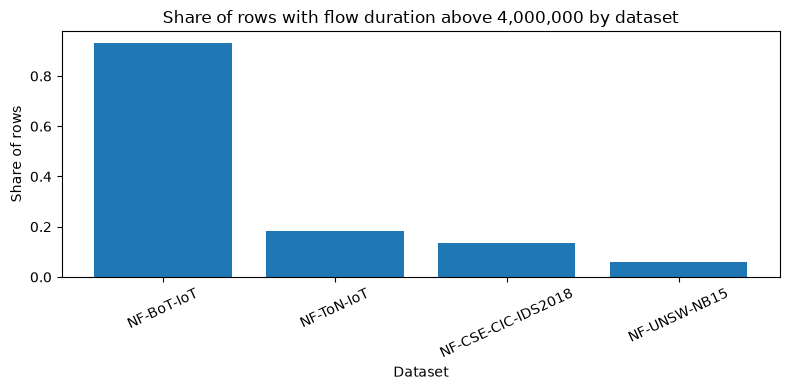

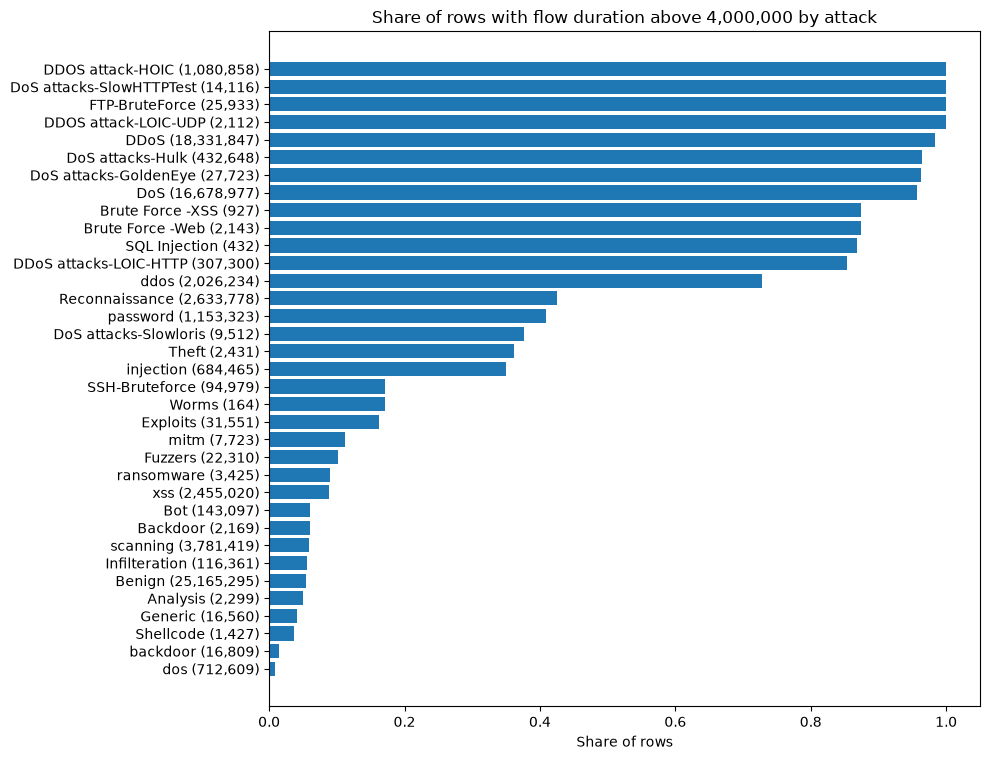

In [22]:
DURATION_TAIL_THRESHOLD = 4000000

duration_by_group = q(f"SELECT Dataset, Attack, COUNT(*) AS rows_total, COUNT(*) FILTER (WHERE FLOW_DURATION_MILLISECONDS > {DURATION_TAIL_THRESHOLD}) AS rows_tail FROM flows GROUP BY Dataset, Attack")
duration_by_group["share"] = duration_by_group["rows_tail"] / duration_by_group["rows_total"]
display(duration_by_group.sort_values("share", ascending=False, kind="stable").reset_index(drop=True))

duration_by_dataset = duration_by_group.groupby("Dataset", as_index=False).agg(rows_total=("rows_total", "sum"), rows_tail=("rows_tail", "sum"))
duration_by_dataset["share"] = duration_by_dataset["rows_tail"] / duration_by_dataset["rows_total"]
duration_by_dataset = duration_by_dataset.sort_values("share", ascending=False, kind="stable")
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(duration_by_dataset["Dataset"], duration_by_dataset["share"])
ax.set_title("Share of rows with flow duration above 4,000,000 by dataset")
ax.set_xlabel("Dataset")
ax.set_ylabel("Share of rows")
ax.tick_params(axis="x", rotation=25)
show_plot(fig)

duration_by_attack = duration_by_group.groupby("Attack", as_index=False).agg(rows_total=("rows_total", "sum"), rows_tail=("rows_tail", "sum"))
duration_by_attack["share"] = duration_by_attack["rows_tail"] / duration_by_attack["rows_total"]
duration_by_attack = duration_by_attack.sort_values("share", ascending=False, kind="stable")
duration_by_attack["attack_label"] = duration_by_attack.apply(lambda row: f"{row['Attack']} ({int(row['rows_total']):,})", axis=1)
fig, ax = plt.subplots(figsize=(10, max(6, 0.22 * len(duration_by_attack))))
ax.barh(duration_by_attack["attack_label"], duration_by_attack["share"])
ax.invert_yaxis()
ax.set_title("Share of rows with flow duration above 4,000,000 by attack")
ax.set_xlabel("Share of rows")
show_plot(fig)

#### Osservazioni
- La quota di righe con `FLOW_DURATION_MILLISECONDS > 4.000.000` è 98,3% per `DDoS` e 95,7% per `DoS` in BoT-IoT; 100% per `DDOS attack-HOIC`, `FTP-BruteForce` e `DoS attacks-SlowHTTPTest` in CSE-CIC; 72,8% per `ddos` in ToN-IoT. Anche i benigni di BoT-IoT sono al 62,9%.
- In CSE-CIC la durata separa bene benigni e attacchi: sopra soglia ci sono il 4,0% dei benigni contro il 100% di tre classi di attacco, e (cap. precedente) gli zeri sono 96,0% contro 17,3%. Rischio di scorciatoia.
- Il massimo 4.294.967 (= ⌊2³²/1000⌋) fa pensare a un valore troncato o saturato, ma l'origine tecnica non è confermata. Mediana: 4.293.811 in BoT-IoT, 0 in CSE-CIC e ToN-IoT.

#### Note per la pulizia
- Non eliminare righe e non confondere la durata zero con la coda estrema. Alternative da confrontare: valore originale, flag sul massimo, flag sopra soglia, mancante se la saturazione viene confermata, feature rimossa.
- Per `DURATION_IN` e `DURATION_OUT` non abbiamo fatto lo stesso controllo.

#### Note per l'addestramento
- Confrontare le alternative con gli stessi split, riportando metriche per fonte e per classe. Le trasformazioni si stimano sul train.

## 6. Correlation

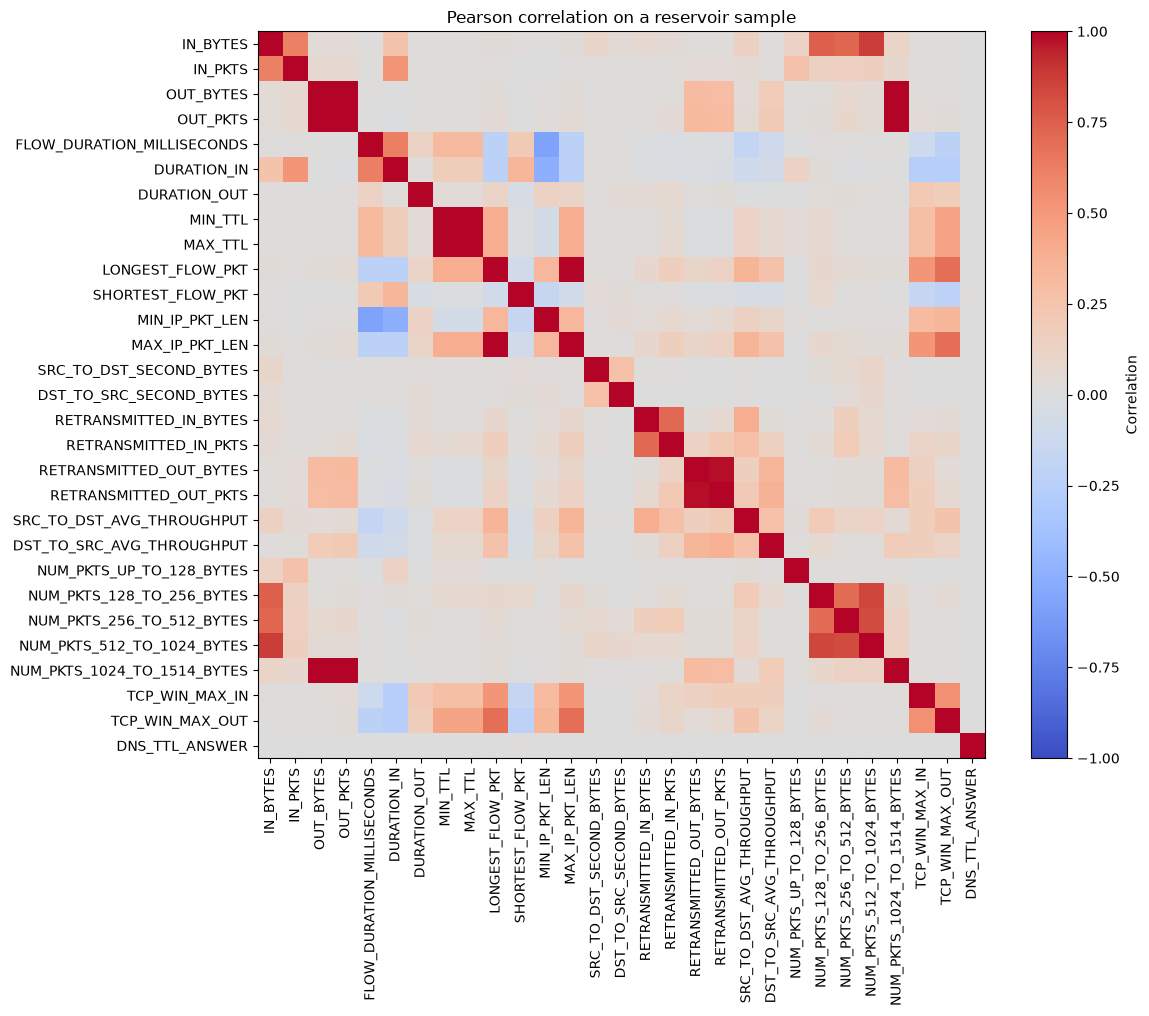

In [23]:
corr_columns = [c for c in continuous if c in ALL_COLUMNS]
correlation_sample = q("SELECT " + ", ".join(sql_ident(c) for c in corr_columns) + " FROM flows USING SAMPLE reservoir(100000 ROWS) REPEATABLE (42)")
corr = correlation_sample.corr(method="pearson")
fig, ax = plt.subplots(figsize=(12, 10))
image = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)), corr.columns, rotation=90)
ax.set_yticks(range(len(corr.index)), corr.index)
ax.set_title("Pearson correlation on a reservoir sample")
fig.colorbar(image, ax=ax, label="Correlation")
show_plot(fig)

In [24]:
correlation_threshold = 0.90
high_correlation_pairs = [(a, b, float(corr.loc[a, b])) for a, b in combinations(corr.columns, 2) if pd.notna(corr.loc[a, b]) and abs(corr.loc[a, b]) >= correlation_threshold]
high_correlation_table = pd.DataFrame(high_correlation_pairs, columns=["feature_a", "feature_b", "pearson_r"]).sort_values("pearson_r", key=lambda values: values.abs(), ascending=False)
display(high_correlation_table)

,feature_a,feature_b,pearson_r
4,LONGEST_FLOW_PKT,MAX_IP_PKT_LEN,1.000000
3,MIN_TTL,MAX_TTL,0.998960
0,OUT_BYTES,OUT_PKTS,0.997496
1,OUT_BYTES,NUM_PKTS_1024_TO_1514_BYTES,0.996135
2,OUT_PKTS,NUM_PKTS_1024_TO_1514_BYTES,0.993221
5,RETRANSMITTED_OUT_BYTES,RETRANSMITTED_OUT_PKTS,0.981286


In [25]:
class_corr_sample = q("SELECT Label, " + ", ".join(sql_ident(c) for c in corr_columns) + " FROM flows USING SAMPLE reservoir(100000 ROWS) REPEATABLE (42)")
benign_corr = class_corr_sample[class_corr_sample["Label"] == 0][corr_columns].corr()
attack_corr = class_corr_sample[class_corr_sample["Label"] == 1][corr_columns].corr()
correlation_changes = []
for a, b in combinations(corr_columns, 2):
    benign_r, attack_r = benign_corr.loc[a, b], attack_corr.loc[a, b]
    if pd.notna(benign_r) and pd.notna(attack_r):
        correlation_changes.append({"feature_a": a, "feature_b": b, "benign_r": benign_r, "attack_r": attack_r, "absolute_change": abs(attack_r - benign_r)})
class_correlation_changes = pd.DataFrame(correlation_changes).sort_values("absolute_change", ascending=False).head(20)
display(class_correlation_changes)

,feature_a,feature_b,benign_r,attack_r,absolute_change
20,IN_BYTES,NUM_PKTS_UP_TO_128_BYTES,0.002470,0.993903,0.991433
47,IN_PKTS,NUM_PKTS_UP_TO_128_BYTES,0.011251,0.999927,0.988676
323,RETRANSMITTED_IN_BYTES,NUM_PKTS_512_TO_1024_BYTES,0.001040,0.908169,0.907129
23,IN_BYTES,NUM_PKTS_512_TO_1024_BYTES,0.996341,0.111427,0.884914
50,IN_PKTS,NUM_PKTS_512_TO_1024_BYTES,0.895277,0.018971,0.876306
21,IN_BYTES,NUM_PKTS_128_TO_256_BYTES,0.865843,0.011369,0.854474
49,IN_PKTS,NUM_PKTS_256_TO_512_BYTES,0.864629,0.018248,0.846381
386,NUM_PKTS_128_TO_256_BYTES,NUM_PKTS_512_TO_1024_BYTES,0.861058,0.018300,0.842758
322,RETRANSMITTED_IN_BYTES,NUM_PKTS_256_TO_512_BYTES,0.076954,0.873804,0.796850
48,IN_PKTS,NUM_PKTS_128_TO_256_BYTES,0.794703,-0.001294,0.795997


#### Osservazioni
- Pearson calcolato su un campione di 100.000 righe, dominato dalle fonti più grandi. Coppie con |r| ≥ 0,90: `LONGEST_FLOW_PKT`–`MAX_IP_PKT_LEN` 1,000; `MIN_TTL`–`MAX_TTL` 0,999; `OUT_BYTES`–`OUT_PKTS` 0,997; `OUT_BYTES` e `OUT_PKTS` con `NUM_PKTS_1024_TO_1514_BYTES` 0,996 e 0,993; `RETRANSMITTED_OUT_BYTES`–`RETRANSMITTED_OUT_PKTS` 0,981.
- La correlazione cambia tra benigni e attacchi: `IN_BYTES`–`NUM_PKTS_UP_TO_128_BYTES` è 0,002 nei benigni e 0,994 negli attacchi. Dato indicativo: campione piccolo e code pesanti.
- Una correlazione calcolata su tutti i dati insieme non prova che due feature siano uguali o ridondanti dentro ogni fonte.

#### Note per la pulizia
- Togliere `MAX_IP_PKT_LEN` solo dopo aver controllato che sia uguale a `LONGEST_FLOW_PKT` riga per riga. Per le altre coppie, valutare fonte per fonte.

#### Note per l'addestramento
- Confrontare il modello con feature ridotte o rapporti contro quello con tutte le feature: costi e benefici dipendono dal modello.

## 7. Network entities

In [30]:
for c in ["IPV4_SRC_ADDR", "IPV4_DST_ADDR"]:
    if c in ALL_COLUMNS:
        display(q(f"SELECT '{c}' AS feature, COUNT(DISTINCT {sql_ident(c)}) AS distinct_values, COUNT(*) FILTER (WHERE {sql_ident(c)} IS NULL) AS null_count FROM flows"))

,feature,distinct_values,null_count
0,IPV4_SRC_ADDR,247700,0


,feature,distinct_values,null_count
0,IPV4_DST_ADDR,40529,0


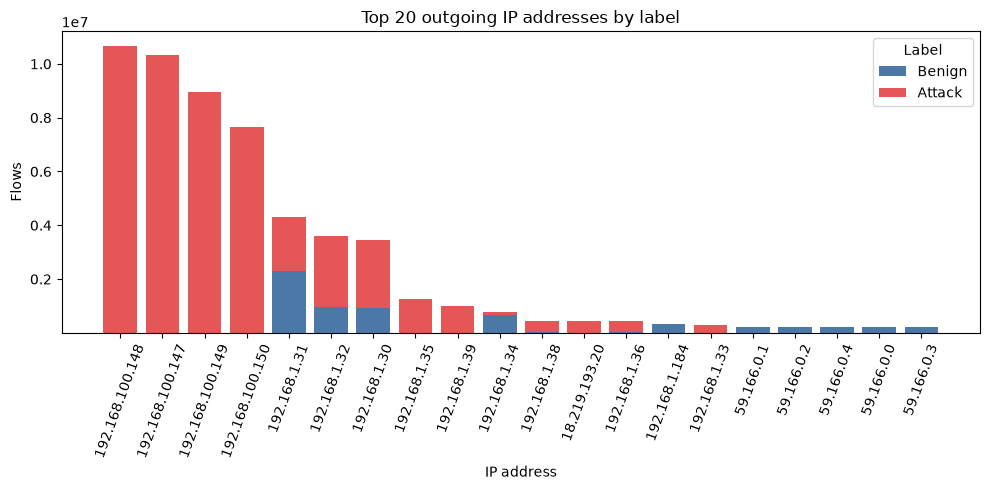

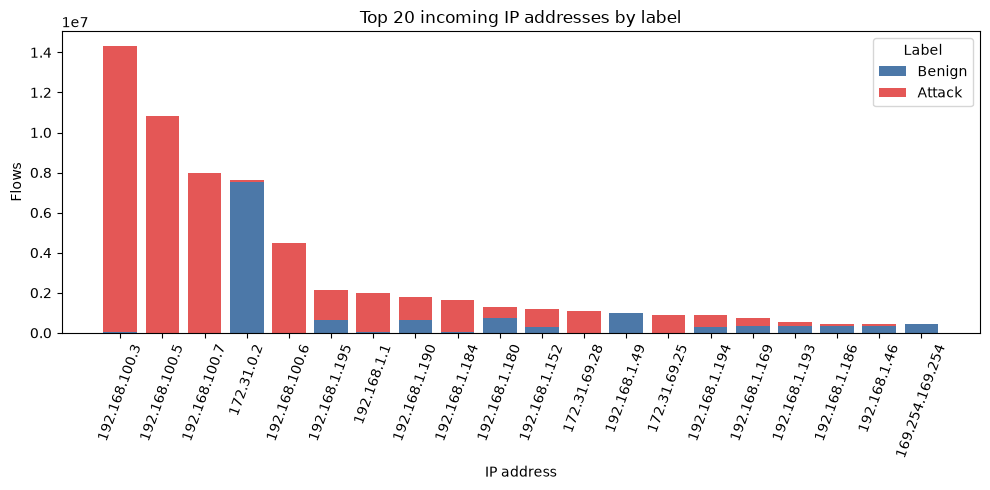

In [31]:
for c, role in [("IPV4_SRC_ADDR", "outgoing"), ("IPV4_DST_ADDR", "incoming")]:
    if c in ALL_COLUMNS:
        top_ips = q(
            f"SELECT {sql_ident(c)} AS ip_address, Label, COUNT(*) AS flows "
            f"FROM flows "
            f"GROUP BY {sql_ident(c)}, Label "
            f"ORDER BY SUM(COUNT(*)) OVER (PARTITION BY {sql_ident(c)}) DESC "
            f"LIMIT 100"
        )

        top_ip_totals = (
            top_ips.groupby("ip_address", as_index=False)["flows"]
            .sum()
            .nlargest(20, "flows")
        )
        top_ip_names = top_ip_totals["ip_address"]
        plot_data = top_ips[top_ips["ip_address"].isin(top_ip_names)]
        plot_data = plot_data.pivot(
            index="ip_address", columns="Label", values="flows"
        ).fillna(0)
        plot_data = plot_data.reindex(top_ip_names)

        fig, ax = plt.subplots(figsize=(10, 5))
        bottom = np.zeros(len(plot_data))

        for label, color, name in [
            (0, "#4C78A8", "Benign"),
            (1, "#E45756", "Attack"),
        ]:
            if label in plot_data.columns:
                ax.bar(
                    plot_data.index.astype(str),
                    plot_data[label],
                    bottom=bottom,
                    color=color,
                    label=name,
                )
                bottom += plot_data[label].to_numpy()

        ax.set_title(f"Top 20 {role} IP addresses by label")
        ax.set_xlabel("IP address")
        ax.set_ylabel("Flows")
        ax.tick_params(axis="x", rotation=70)
        ax.legend(title="Label")
        show_plot(fig)

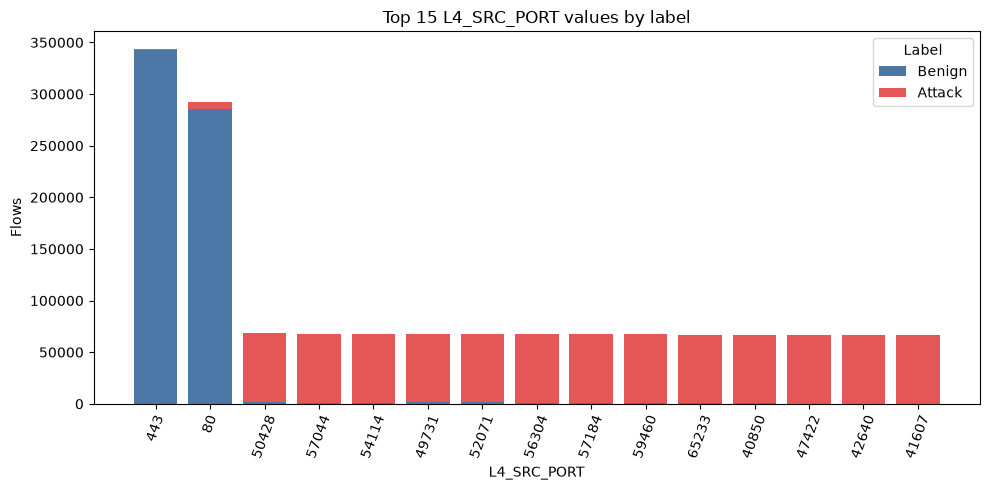

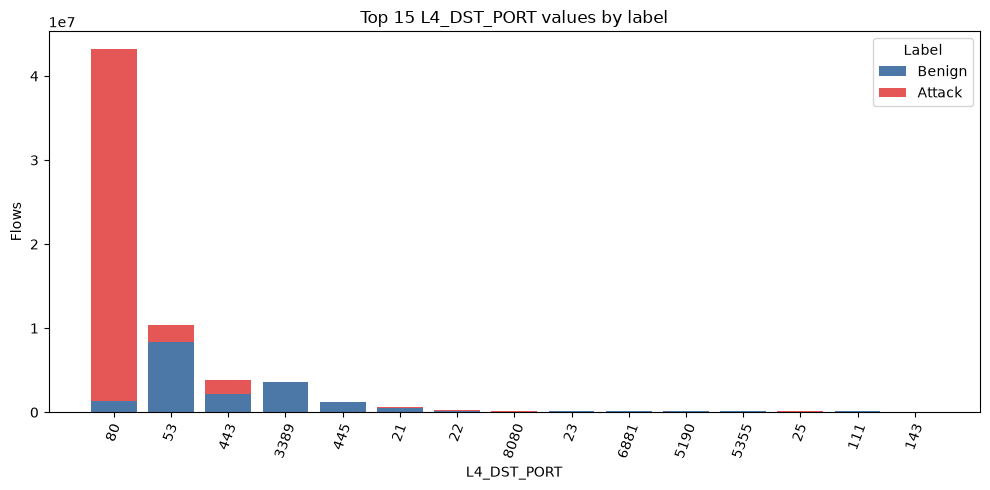

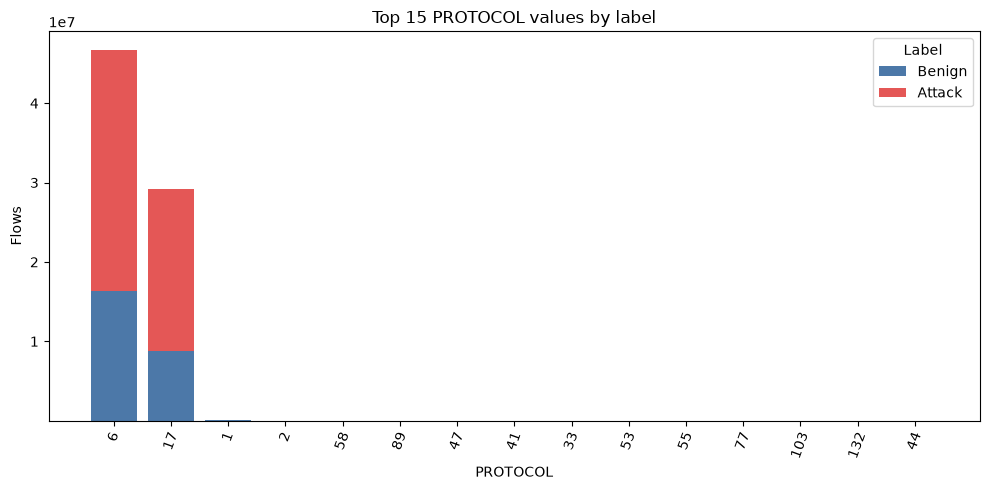

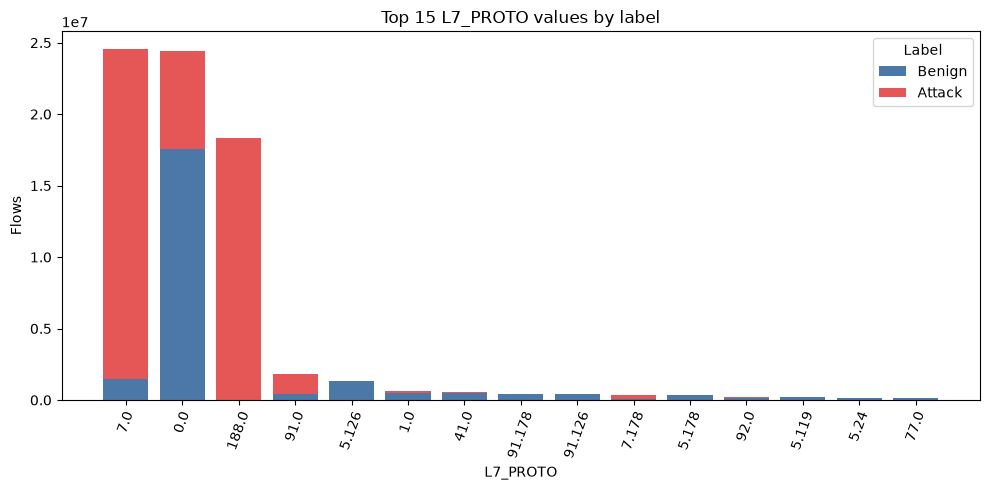

In [32]:
for c in ["L4_SRC_PORT", "L4_DST_PORT", "PROTOCOL", "L7_PROTO"]:
    if c in ALL_COLUMNS:
        port_counts = q(
            f"SELECT {sql_ident(c)} AS value, Label, COUNT(*) AS rows "
            f"FROM flows "
            f"GROUP BY {sql_ident(c)}, Label"
        )

        top_values = (
            port_counts.groupby("value", as_index=False)["rows"]
            .sum()
            .nlargest(15, "rows")["value"]
        )
        plot_data = port_counts[port_counts["value"].isin(top_values)]
        plot_data = plot_data.pivot(
            index="value", columns="Label", values="rows"
        ).fillna(0)
        plot_data = plot_data.reindex(top_values)

        fig, ax = plt.subplots(figsize=(10, 5))
        bottom = np.zeros(len(plot_data))

        for label, color, name in [
            (0, "#4C78A8", "Benign"),
            (1, "#E45756", "Attack"),
        ]:
            if label in plot_data.columns:
                ax.bar(
                    plot_data.index.astype(str),
                    plot_data[label],
                    bottom=bottom,
                    color=color,
                    label=name,
                )
                bottom += plot_data[label].to_numpy()

        ax.set_title(f"Top 15 {c} values by label")
        ax.set_xlabel(c)
        ax.set_ylabel("Flows")
        ax.tick_params(axis="x", rotation=70)
        ax.legend(title="Label")
        show_plot(fig)

In [33]:
if {"IPV4_SRC_ADDR", "IPV4_DST_ADDR", "L4_DST_PORT", "PROTOCOL"}.issubset(ALL_COLUMNS):
    source_ip_summary = q("SELECT IPV4_SRC_ADDR AS source_ip, COUNT(*) AS flows, COUNT(DISTINCT IPV4_DST_ADDR) AS distinct_destinations, COUNT(DISTINCT L4_DST_PORT) AS distinct_destination_ports, COUNT(DISTINCT PROTOCOL) AS distinct_protocols FROM flows GROUP BY IPV4_SRC_ADDR ORDER BY flows DESC LIMIT 100")
    display(source_ip_summary)
# Full-table grouping by source IP may be expensive.

,source_ip,flows,distinct_destinations,distinct_destination_ports,distinct_protocols
0,192.168.100.148,10676772,13,65536,3
1,192.168.100.147,10342482,13,65536,3
2,192.168.100.149,8961517,13,65536,3
3,192.168.100.150,7671380,14,65536,3
4,192.168.1.31,4308656,414,5204,3
5,192.168.1.32,3614669,299,65536,3
6,192.168.1.30,3462837,373,65536,3
7,192.168.1.35,1254234,43,15,3
8,192.168.1.39,983745,34,6332,3
9,192.168.1.34,778418,334,1086,3


In [34]:
ip_class = q("SELECT Dataset, IPV4_SRC_ADDR, COUNT(DISTINCT Label) AS label_count, MIN(Label) AS only_label FROM flows GROUP BY Dataset, IPV4_SRC_ADDR")
ip_shortcut = ip_class.groupby(["Dataset", "label_count"], as_index=False).size().pivot(index="Dataset", columns="label_count", values="size").fillna(0).rename(columns={1: "source_ips_one_label", 2: "source_ips_both_labels"}).reset_index()
if "source_ips_one_label" in ip_shortcut.columns:
    ip_shortcut["source_ips_only_label_0"] = [int(((ip_class.Dataset == d) & (ip_class.label_count == 1) & (ip_class.only_label == 0)).sum()) for d in ip_shortcut.Dataset]
    ip_shortcut["source_ips_only_label_1"] = [int(((ip_class.Dataset == d) & (ip_class.label_count == 1) & (ip_class.only_label == 1)).sum()) for d in ip_shortcut.Dataset]
display(ip_shortcut)
# This full-table aggregation measures potential source-IP shortcut learning.

label_count,Dataset,source_ips_one_label,source_ips_both_labels,source_ips_only_label_0,source_ips_only_label_1
0,NF-BoT-IoT,12,8,12,0
1,NF-CSE-CIC-IDS2018,224017,551,223920,97
2,NF-ToN-IoT,23055,24,23048,7
3,NF-UNSW-NB15,36,4,36,0


In [35]:
port_class = q("SELECT Dataset, L4_DST_PORT, COUNT(DISTINCT Label) AS label_count, MIN(Label) AS only_label FROM flows GROUP BY Dataset, L4_DST_PORT")
port_shortcut = port_class.groupby(["Dataset", "label_count"], as_index=False).size().pivot(index="Dataset", columns="label_count", values="size").fillna(0).rename(columns={1: "destination_ports_one_label", 2: "destination_ports_both_labels"}).reset_index()
for label in [0, 1]:
    port_shortcut[f"destination_ports_only_label_{label}"] = [int(((port_class.Dataset == d) & (port_class.label_count == 1) & (port_class.only_label == label)).sum()) for d in port_shortcut.Dataset]
display(port_shortcut)
# This full-table aggregation measures potential destination-port shortcut learning.

label_count,Dataset,destination_ports_one_label,destination_ports_both_labels,destination_ports_only_label_0,destination_ports_only_label_1
0,NF-BoT-IoT,16235,49301,0,16235
1,NF-CSE-CIC-IDS2018,34904,1405,34665,239
2,NF-ToN-IoT,27375,38161,0,27375
3,NF-UNSW-NB15,61682,2943,61645,37


In [36]:
ip_overlap = q("SELECT IPV4_SRC_ADDR AS ip_address, COUNT(DISTINCT Dataset) AS dataset_count FROM flows GROUP BY IPV4_SRC_ADDR HAVING COUNT(DISTINCT Dataset) > 1")
print(f"Source IPs appearing in multiple datasets: {len(ip_overlap):,}")
display(ip_overlap.groupby("dataset_count").size().rename("source_ips").reset_index())
# Counting distinct IPs across the full table may be expensive.

Source IPs appearing in multiple datasets: 6


,dataset_count,source_ips
0,2,5
1,3,1


#### Osservazioni
- Ci sono 247.700 IP sorgente e 40.529 IP destinazione. Solo 6 IP sorgente compaiono in più fonti: le reti sono quasi separate, quindi un grafo unico equivale a quattro componenti.
- `18.219.193.20` ha 432.648 flussi, una sola label e una sola destinazione. È esattamente il numero di righe di `DoS attacks-Hulk`, quindi questo IP identifica la classe.
- In CSE-CIC il 99,75% degli IP sorgente ha una sola etichetta (223.920 solo benigni, 97 solo attacco). BoT-IoT ha 20 IP sorgente (12 solo benigni, 8 con entrambe). Porte destinazione: BoT-IoT 16.235 solo attacco e nessuna solo benigna, ToN-IoT 27.375 solo attacco, UNSW-NB15 61.645 solo benigne. Sono conteggi di valori distinti, non pesati per numero di flussi.
- `L7_PROTO` = 188 compare in 18.331.497 righe di BoT-IoT (cap. 5), quasi quanto i 18.331.847 flussi `DDoS`. `[ipotesi]` è una scorciatoia quasi perfetta per quella classe, ancora da verificare.
- IP e porte possono descrivere anche un comportamento o un servizio, non solo identificare. Se il modello li memorizza si vede solo con split dedicati.

#### Note per la pulizia
- Trattare gli IP come chiavi `(Dataset, IP)`. Confrontare porte discretizzate, categoriali o escluse. Gli aggregati vanno calcolati senza far entrare informazioni del test.

#### Note per l'addestramento
- Confrontare split per IP e split casuali.
- Sequenze per host solo se l'ordine temporale è verificato. Per la GNN, decidere come trattare gli hub.